In [2]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)

categories = ['Dairy', 'Bakery', 'Fresh produce', 'Pantry', 'Meat', 'Household']
promo_rate = {'Dairy': 0.12, 'Bakery': 0.12, 'Fresh produce': 0.12,
              'Pantry': 0.15, 'Meat': 0.15, 'Household': 0.25}

max_discount = {'Household': 0.40}
store_uplift = {'Metro': 1.00, 'Regional': 1.04}

n_products, n_weeks = 50, 52
weeks = pd.date_range(start='2025-01-06', periods=n_weeks, freq='W-MON')

products = pd.DataFrame({
    'product_id': np.arange(1, n_products + 1),
    'category': rng.choice(categories, size=n_products),
    'base_price': rng.lognormal(mean=1.5, sigma=0.5, size=n_products).round(2),
})
products.head()

,product_id,category,base_price
0,1,Dairy,3.76
1,2,Meat,5.85
2,3,Pantry,5.38
3,4,Fresh produce,5.51
4,5,Fresh produce,5.56


In [3]:
rows = []
for p in products.itertuples():
    regular = p.base_price
    for week in weeks:
        regular *= 1 + rng.normal(0, 0.005)  # small weekly drift
        on_promo = rng.random() < promo_rate[p.category]
        depth = rng.uniform(0.10, max_discount.get(p.category, 0.30)) if on_promo else 0.0
        for store, uplift in store_uplift.items():
            store_regular = regular * uplift * (1 + rng.normal(0, 0.02))
            rows.append({
                'product_id': p.product_id,
                'category': p.category,
                'week': week,
                'store_group': store,
                'regular_price': round(store_regular, 2),
                'shelf_price': round(store_regular * (1 - depth), 2),
                'on_promo': on_promo,
                'discount_depth': round(depth, 3),
            })
        if on_promo and rng.random() < 0.3:
            regular *= 1.03  # small creep after some promotions

df = pd.DataFrame(rows)

In [4]:
df.to_csv('data/simulated_prices.csv', index=False)
print(df.shape)
df.head()

(5200, 8)


,product_id,category,week,store_group,regular_price,shelf_price,on_promo,discount_depth
0,1,Dairy,2025-01-06,Metro,3.78,3.78,False,0.0
1,1,Dairy,2025-01-06,Regional,3.97,3.97,False,0.0
2,1,Dairy,2025-01-13,Metro,3.72,3.72,False,0.0
3,1,Dairy,2025-01-13,Regional,3.89,3.89,False,0.0
4,1,Dairy,2025-01-20,Metro,3.80,3.80,False,0.0


In [5]:
df[(df['category'] == 'Dairy') & (df['on_promo'])].head()

,product_id,category,week,store_group,regular_price,shelf_price,on_promo,discount_depth
10,1,Dairy,2025-02-10,Metro,3.76,2.66,True,0.292
11,1,Dairy,2025-02-10,Regional,3.81,2.70,True,0.292
14,1,Dairy,2025-02-24,Metro,3.93,2.83,True,0.281
15,1,Dairy,2025-02-24,Regional,3.88,2.79,True,0.281
20,1,Dairy,2025-03-17,Metro,3.87,3.16,True,0.183


In [6]:
df.groupby('category')['shelf_price'].mean().round(2)

category
Bakery           4.62
Dairy            4.90
Fresh produce    5.19
Household        5.67
Meat             4.58
Pantry           5.42
Name: shelf_price, dtype: float64

In [7]:
promo_counts = (df[df['store_group'] == 'Metro']
                .groupby('product_id')['on_promo'].sum()
                .rename('promo_weeks').reset_index())
products.merge(promo_counts, on='product_id').head()

,product_id,category,base_price,promo_weeks
0,1,Dairy,3.76,10
1,2,Meat,5.85,16
2,3,Pantry,5.38,9
3,4,Fresh produce,5.51,5
4,5,Fresh produce,5.56,4


In [8]:
promo_counts = (df[df['store_group'] == 'Metro']
                .groupby('product_id')['on_promo'].sum()
                .rename('promo_weeks').reset_index())
products.merge(promo_counts, on='product_id').head()

,product_id,category,base_price,promo_weeks
0,1,Dairy,3.76,10
1,2,Meat,5.85,16
2,3,Pantry,5.38,9
3,4,Fresh produce,5.51,5
4,5,Fresh produce,5.56,4


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('data/simulated_prices.csv', parse_dates=['week'])
metro = df[df['store_group'] == 'Metro']  # one row per product-week

print(metro['shelf_price'].describe())
print('skew:', round(metro['shelf_price'].skew(), 2))

count    2600.000000
mean        4.950619
std         2.095450
min         1.420000
25%         3.460000
50%         4.790000
75%         6.060000
max        15.850000
Name: shelf_price, dtype: float64
skew: 1.54


In [2]:
summary = (metro.groupby('category')['shelf_price']
           .agg(['count', 'mean', 'median', 'std', 'min', 'max']).round(2))
print(summary)
print(metro['shelf_price'].quantile([0.05, 0.25, 0.5, 0.75, 0.95]).round(2))

               count  mean  median   std   min    max
category                                             
Bakery           208  4.54    4.46  1.10  2.38   6.29
Dairy            416  4.80    3.94  2.29  1.42  10.20
Fresh produce    468  5.08    5.51  1.63  1.87   8.41
Household        416  5.55    4.34  3.47  1.44  15.85
Meat             676  4.49    4.38  1.46  1.50   7.31
Pantry           416  5.31    5.38  1.48  1.97   8.77
0.05    2.23
0.25    3.46
0.50    4.79
0.75    6.06
0.95    8.15
Name: shelf_price, dtype: float64


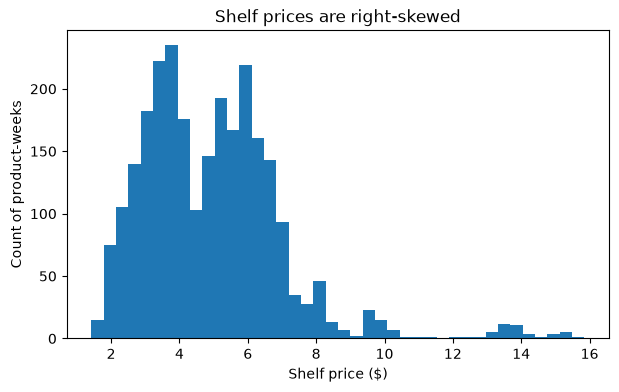

Price Range: $9.72 - $10.08 | Count: 15.0
Price Range: $10.08 - $10.44 | Count: 7.0
Price Range: $10.44 - $10.80 | Count: 1.0


In [15]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(metro['shelf_price'], bins=40)
ax.set_xlabel('Shelf price ($)')
ax.set_ylabel('Count of product-weeks')
ax.set_title('Shelf prices are right-skewed')
plt.show()
counts, bins, patches = ax.hist(metro['shelf_price'], bins=40)

# Loop through and print the bin ranges and their counts
for i, count in enumerate(counts):
    if bins[i] <= 10.5 and bins[i+1] >= 10:
        print(f"Price Range: ${bins[i]:.2f} - ${bins[i+1]:.2f} | Count: {count}")

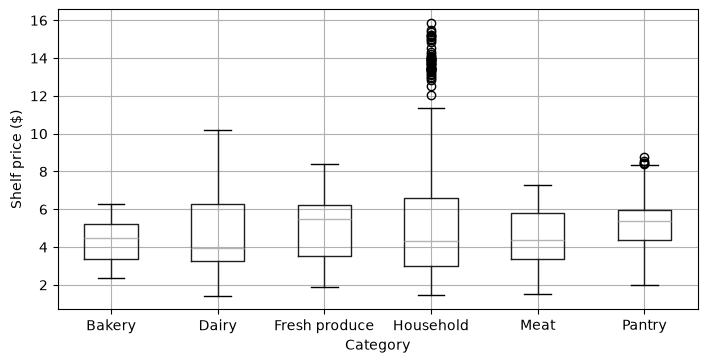

In [11]:

fig, ax = plt.subplots(figsize=(8, 4))
metro.boxplot(column='shelf_price', by='category', ax=ax)
ax.set_title('')
fig.suptitle('')
ax.set_xlabel('Category')
ax.set_ylabel('Shelf price ($)')
plt.show()

In [16]:
q1, q3 = metro['shelf_price'].quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = metro[(metro['shelf_price'] < low) | (metro['shelf_price'] > high)]
print('IQR bounds:', round(low, 2), round(high, 2))
print('outlier rows:', len(outliers), 'of', len(metro), '| products:', outliers['product_id'].nunique())

IQR bounds: -0.44 9.96
outlier rows: 58 of 2600 | products: 2


In [19]:
def count_iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

metro.groupby('category')['shelf_price'].apply(count_iqr_outliers)


category
Bakery            0
Dairy             0
Fresh produce     0
Household        46
Meat              0
Pantry            5
Name: shelf_price, dtype: int64

### Observations from the charts

- Half of all product-weeks sit between $3.46 and $6.06, but the distribution is right-skewed (skew 1.54), so the mean ($4.95) is above the median ($4.79).
- Household has the widest spread (standard deviation 3.47), followed by Dairy (2.29). Both contain the most expensive individual products (maximums $15.85 and $10.20), which pull their means above their medians. Dairy's median ($3.94) is the lowest of any category, so a typical Dairy item is cheap.
- Meat has the most products (13); Bakery has the fewest (4).
- Across all prices together, 58 rows exceed the IQR upper bound of $9.96: 51 from one Household product and 7 from a Dairy product that only just crosses it (maximum $10.20).
- Within each category, only Household (46 rows) and Pantry (5 rows) have outliers, matching the boxplot. The result depends on what you compare against, so I state which rule I used. I would not delete any of these.
- With only 4 to 13 products per category, a single product can shift a category's average.